In [1]:
!pip install monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 10.1 MB/s eta 0:00:00


In [2]:
import copy
import gc
import itertools
import json
import math
import os
import random
import shutil
import tarfile
import time
from contextlib import nullcontext
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.colors import ListedColormap
from monai.inferers import sliding_window_inference
from scipy import ndimage as ndi
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

In [3]:
@dataclass
class Config:
    seed: int = 42
    split_seed: int = 42
    input_root: str = "/kaggle/input/datasets/dschettler8845/brats-2021-task1"
    output_root: str = os.environ.get("MOREG_OUTPUT", "/kaggle/working/moreg")
    restore_from: tuple = ()
    smoke_test: bool = False
    run_training: bool = True
    run_baseline: bool = False
    run_student: bool = False
    run_missing_modalities: bool = False
    run_seed_repeats: bool = True
    extra_seeds: tuple = (7, 2026)
    run_ablations: bool = True
    ablations: tuple = ("no_gate", "no_context", "uniform_fusion")
    only_runs: tuple = ()
    session_hours: float = 10.5
    et_postprocess: bool = True
    et_volume_grid: tuple = (0, 25, 50, 100, 150, 200, 300, 400, 500, 750, 1000)
    resume_path: str = ""
    roi: tuple = (96, 96, 96)
    base: int = 24
    batch_size: int = 1
    accumulate: int = 2
    epochs: int = 125
    student_epochs: int = 40
    max_train_batches: int = 250
    workers: int = 2
    lr: float = 3e-4
    min_lr: float = 1e-6
    weight_decay: float = 1e-4
    warmup_epochs: int = 10
    val_every: int = 5
    patience_checks: int = 15
    ema_decay: float = 0.99
    amp: bool = True
    train_fraction: float = 0.70
    val_fraction: float = 0.15
    foreground_prob: float = 0.75
    cache_gb: float = 8.0
    overlap: float = 0.5
    sw_batch_size: int = 1
    tta: bool = False
    threshold: float = 0.5
    surface_tolerance_mm: float = 1.0
    bootstrap_samples: int = 2000
    save_nifti_count: int = 3
    deterministic: bool = False


cfg = Config()
if cfg.smoke_test:
    cfg = replace(
        cfg,
        roi=(32, 32, 32),
        base=4,
        epochs=2,
        student_epochs=2,
        max_train_batches=3,
        workers=0,
        accumulate=2,
        val_every=1,
        warmup_epochs=1,
        bootstrap_samples=100,
        cache_gb=0.05,
        extra_seeds=(7,),
        et_volume_grid=(0, 5, 50),
    )

assert 0 < cfg.train_fraction < 1 and 0 < cfg.val_fraction < 1 - cfg.train_fraction
assert all(v >= 16 and v % 8 == 0 for v in cfg.roi)
assert cfg.epochs > 0 and cfg.accumulate > 0
assert cfg.seed not in cfg.extra_seeds, "extra_seeds must differ from the reference seed"
assert 0 in cfg.et_volume_grid, "the grid must contain 0 (no post-processing) as a candidate"
OUT = Path(cfg.output_root) / ("smoke" if cfg.smoke_test else "full")
OUT.mkdir(parents=True, exist_ok=True)
SESSION_START = time.time()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODALITIES = ("t1", "t1ce", "t2", "flair")
REGIONS = ("WT", "TC", "ET")


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = not cfg.deterministic
    torch.backends.cudnn.deterministic = cfg.deterministic
    torch.use_deterministic_algorithms(cfg.deterministic, warn_only=True)


def run_progress(run_dir):
    run_dir = Path(run_dir)
    if (run_dir / "complete.json").exists():
        return math.inf
    history = run_dir / "history.csv"
    if not history.exists():
        return -1
    epochs = pd.read_csv(history).epoch
    return int(epochs.max()) if len(epochs) else -1


def restore_previous_outputs():
    for src in cfg.restore_from:
        src = Path(src)
        if not (src / "patient_split.csv").exists():
            raise FileNotFoundError(f"{src} is not a '.../moreg/full' output folder")
        for fname in ("patient_split.csv", "split_protocol.npz"):
            if not (OUT / fname).exists():
                shutil.copy2(src / fname, OUT / fname)
        for run_dir in sorted(p for p in src.iterdir() if p.is_dir()):
            if not (run_dir / "history.csv").exists():
                continue
            dst = OUT / run_dir.name
            if run_progress(run_dir) > run_progress(dst):
                if dst.exists():
                    shutil.rmtree(dst)
                shutil.copytree(run_dir, dst)
                print(f"Restored {run_dir.name} from {src} (progress: {run_progress(dst)})")


if not cfg.smoke_test:
    restore_previous_outputs()
seed_all(cfg.seed)

In [4]:
def amp_context():
    return (
        torch.autocast("cuda", dtype=torch.float16)
        if cfg.amp and DEVICE.type == "cuda"
        else nullcontext()
    )


def atomic_write(path, writer):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    with open(temp, "wb") as handle:
        writer(handle)
    temp.replace(path)


def atomic_npy(path, array):
    atomic_write(path, lambda handle: np.save(handle, array))


def atomic_npz(path, **arrays):
    atomic_write(path, lambda handle: np.savez(handle, **arrays))


def atomic_csv(frame, path):
    atomic_write(path, lambda handle: frame.to_csv(handle, index=False))


if DEVICE.type == "cpu" and not cfg.smoke_test:
    print("full 3D training on CPU will be very slow. Enable a Kaggle GPU.")

In [5]:
def extract_archive(archive, dest):
    archive, dest = Path(archive), Path(dest)

    marker = dest / f".complete_{archive.stat().st_size}"
    if marker.exists():
        return
    if dest.exists():
        shutil.rmtree(dest)
    dest.mkdir(parents=True)
    with tarfile.open(archive, "r:*") as tf:
        members = tf.getmembers()
        for m in members:
            target = (dest / m.name).resolve()
            if not target.is_relative_to(dest.resolve()) or not (m.isfile() or m.isdir()):
                raise ValueError(f"Unsafe archive member: {m.name}")
        required = sum(m.size for m in members if m.isfile())
        if shutil.disk_usage(dest).free < required + 1024**3:
            raise OSError(f"Insufficient free disk to extract {archive.name}")
        tf.extractall(dest, members=members, filter="data")
    marker.touch()


def discover(root):
    result = {}
    anchors = sorted(Path(root).rglob("*_flair.nii*"))
    for f in anchors:
        if not (f.name.endswith(".nii") or f.name.endswith(".nii.gz")):
            continue
        cid = f.name.split("_flair.nii")[0]
        paths = {}
        for suffix in (*MODALITIES, "seg"):
            matches = [f.parent / f"{cid}_{suffix}{ext}" for ext in (".nii.gz", ".nii")]
            existing = [p for p in matches if p.is_file()]
            if len(existing) != 1:
                raise ValueError(f"{cid}: expected exactly one {suffix}, found {existing}")
            paths[suffix] = str(existing[0])
        if cid in result:
            raise ValueError(f"Duplicate patient {cid} under {root}; attach one dataset copy.")
        result[cid] = {
            "case_id": cid,
            "image": [paths[m] for m in MODALITIES],
            "label": paths["seg"],
        }
    return result


DATA_ROOT = Path(cfg.input_root)
TRAIN_TAR = DATA_ROOT / "BraTS2021_Training_Data.tar"
FIX_TARS = [DATA_ROOT / "BraTS2021_00495.tar", DATA_ROOT / "BraTS2021_00621.tar"]

for archive in (TRAIN_TAR, *FIX_TARS):
    if not archive.is_file():
        raise FileNotFoundError(f"Missing BraTS 2021 archive: {archive}")

extract_archive(TRAIN_TAR, OUT / "extracted" / "training")
case_map = discover(OUT / "extracted" / "training")

for archive in FIX_TARS:
    fix_dir = OUT / "extracted" / archive.stem
    extract_archive(archive, fix_dir)
    case_map.update(discover(fix_dir))

cases = [case_map[k] for k in sorted(case_map)]
if not cases:
    raise FileNotFoundError(f"No complete labeled cases found under {DATA_ROOT}")
if cfg.smoke_test:
    cases = cases[: min(12, len(cases))]
if len(cases) < 8:
    raise ValueError("At least 8 patients are required for meaningful three-way splitting.")

PREPROCESS_VERSION = "ras-4ch-zscore-braincrop"

In [6]:
def load_case(case):
    ims = [nib.as_closest_canonical(nib.load(p)) for p in case["image"]]
    seg = nib.as_closest_canonical(nib.load(case["label"]))
    shape, affine = ims[0].shape, ims[0].affine
    if len(shape) != 3:
        raise ValueError(f"{case['case_id']}: expected 3D NIfTI, found {shape}")
    for im in [*ims, seg]:
        if im.shape != shape or not np.allclose(im.affine, affine, atol=1e-4):
            raise ValueError(f"{case['case_id']}: modalities/mask geometry mismatch")

    x = np.stack([im.get_fdata(dtype=np.float32) for im in ims], axis=0)
    raw_y = seg.get_fdata(dtype=np.float32)
    if not np.isfinite(x).all() or not np.isfinite(raw_y).all():
        raise ValueError("Non-finite NIfTI values")
    if not set(np.unique(raw_y)).issubset({0.0, 1.0, 2.0, 4.0}):
        raise ValueError(f"Unexpected labels: {np.unique(raw_y)}")
    y = raw_y.astype(np.uint8)
    brain = np.any(x != 0, axis=0)
    if not brain.any():
        raise ValueError("All modalities are empty")
    coords = np.where(brain)
    lo = [max(0, int(c.min()) - 2) for c in coords]
    hi = [min(shape[a], int(c.max()) + 3) for a, c in enumerate(coords)]
    box = tuple(slice(a, b) for a, b in zip(lo, hi))
    if np.count_nonzero(y[box]) != np.count_nonzero(y):
        raise ValueError(f"{case['case_id']}: label outside image foreground crop")
    x, y = x[(slice(None),) + box].copy(), y[box].copy()
    for m in range(4):
        mask = x[m] != 0
        if not mask.any():
            raise ValueError(f"{case['case_id']}: empty {MODALITIES[m]}")
        values = x[m][mask]
        low, high = np.percentile(values, [0.5, 99.5])
        values = np.clip(values, low, high)
        x[m][mask] = (values - values.mean()) / max(float(values.std()), 1e-6)
    spacing = np.asarray(nib.affines.voxel_sizes(affine), dtype=float)
    direction = affine[:3, :3] / spacing[None, :]
    if not np.allclose(direction.T @ direction, np.eye(3), atol=1e-4):
        raise ValueError(
            "Sheared affine: resample to an orthogonal grid before distance evaluation"
        )
    meta = dict(
        case_id=case["case_id"],
        shape=list(shape),
        lo=lo,
        hi=hi,
        spacing=spacing.tolist(),
        affine=affine.tolist(),
    )
    assert x.shape[0] == 4 and x.ndim == 4 and x.shape[1:] == y.shape
    return x, y, meta


CACHE = OUT / "cache"
CACHE.mkdir(exist_ok=True)
cache_limit = int(cfg.cache_gb * 1024**3)
cache_used = sum(p.stat().st_size for p in CACHE.glob("*") if p.is_file())

In [7]:
def cache_files(case):
    stem = f"{case['case_id']}_{PREPROCESS_VERSION}"
    return tuple(CACHE / f"{stem}_{part}" for part in ("x.npy", "y.npy", "meta.npz"))


def load_meta(path):
    with np.load(path) as saved:
        return {key: saved[key].tolist() for key in saved.files}


def get_case(case, allow_cache=False):
    global cache_used
    x_path, y_path, meta_path = cache_files(case)

    if meta_path.exists():
        return np.load(x_path, mmap_mode="r"), np.load(y_path, mmap_mode="r"), load_meta(meta_path)
    x, y, meta = load_case(case)
    size = x.nbytes + y.nbytes + 10000
    has_room = cache_used + size <= cache_limit
    has_disk = shutil.disk_usage(CACHE).free > size + 2 * 1024**3
    if allow_cache and has_room and has_disk:
        atomic_npy(x_path, x)
        atomic_npy(y_path, y)
        atomic_npz(meta_path, **meta)
        cache_used += size
    return x, y, meta


audit_rows = []
for c in tqdm(cases, desc="Audit geometry, labels, and tumor volumes"):
    x, y, meta = get_case(c, allow_cache=True)
    audit_rows.append(
        dict(
            case_id=c["case_id"],
            ET_present=bool((y == 4).any()),
            WT_ml=float(np.count_nonzero(y) * np.prod(meta["spacing"]) / 1000),
            shape=str(meta["shape"]),
            spacing=str(meta["spacing"]),
        )
    )
audit = pd.DataFrame(audit_rows)
audit.to_csv(OUT / "data_audit.csv", index=False)
print(f"Validated {len(cases)} patients; disk cache {cache_used/1024**3:.2f} GiB")
display(audit.head())

Audit geometry, labels, and tumor volumes:   0%|          | 0/1251 [00:00<?, ?it/s]

Validated 1251 patients; disk cache 4.98 GiB


,case_id,ET_present,WT_ml,shape,spacing
0,BraTS2021_00000,True,57.305,"[240, 240, 155]","[1.0, 1.0, 1.0]"
1,BraTS2021_00002,True,190.594,"[240, 240, 155]","[1.0, 1.0, 1.0]"
2,BraTS2021_00003,True,99.239,"[240, 240, 155]","[1.0, 1.0, 1.0]"
3,BraTS2021_00005,True,124.783,"[240, 240, 155]","[1.0, 1.0, 1.0]"
4,BraTS2021_00006,True,137.911,"[240, 240, 155]","[1.0, 1.0, 1.0]"


split
test     188
train    875
val      188
dtype: int64


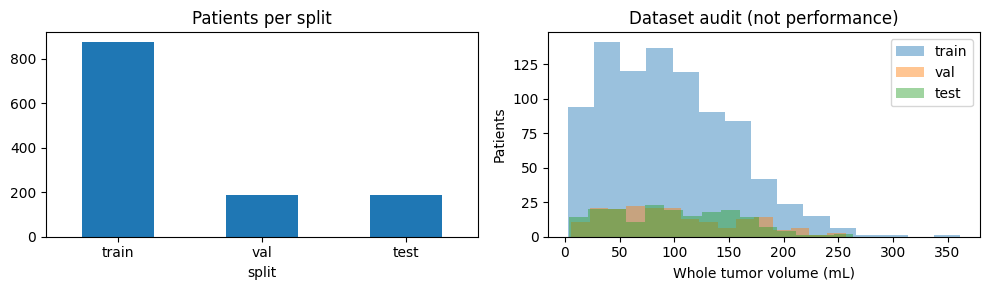

In [8]:
SPLIT_NAMES = ("train", "val", "test")
split_path = OUT / "patient_split.csv"
protocol_path = OUT / "split_protocol.npz"
ids = sorted(c["case_id"] for c in cases)
strata = audit.set_index("case_id")["ET_present"].to_dict()


def partition(items, test_size, seed):
    labels = [strata[i] for i in items]
    try:
        return train_test_split(items, test_size=test_size, random_state=seed, stratify=labels)
    except ValueError as exc:
        print("ET stratification unavailable for this split; using seeded random partition:", exc)
        return train_test_split(items, test_size=test_size, random_state=seed)


def same_arrays(first, second):
    return first.keys() == second.keys() and all(
        np.array_equal(first[key], second[key]) for key in first
    )


protocol = dict(
    ids=np.array(ids),
    seed=cfg.split_seed,
    train_fraction=cfg.train_fraction,
    val_fraction=cfg.val_fraction,
)
if split_path.exists():
    with np.load(protocol_path) as saved:
        saved_protocol = {key: saved[key] for key in saved.files}
    if not same_arrays(saved_protocol, protocol):
        raise ValueError(
            "Dataset/split config changed. Choose a new output_root, do not overwrite test membership."
        )
    splits = pd.read_csv(split_path, dtype={"case_id": str})
else:
    train_ids, rest = partition(ids, 1 - cfg.train_fraction, cfg.split_seed)
    val_fraction_of_rest = round(
        (1 - cfg.train_fraction - cfg.val_fraction) / (1 - cfg.train_fraction), 6
    )
    val_ids, test_ids = partition(rest, val_fraction_of_rest, cfg.split_seed + 1)
    splits = pd.DataFrame(
        [
            (case_id, name)
            for name, group in zip(SPLIT_NAMES, (train_ids, val_ids, test_ids))
            for case_id in group
        ],
        columns=["case_id", "split"],
    ).sort_values("case_id")
    splits.to_csv(split_path, index=False)
    atomic_npz(protocol_path, **protocol)
assert splits.case_id.is_unique and set(splits.case_id) == set(ids)
assert set(splits.split) == set(SPLIT_NAMES)

_ordered = splits.sort_values("case_id")
SPLIT_RECORD = dict(
    ids=_ordered.case_id.to_numpy(dtype=str),
    codes=_ordered.split.map({name: i for i, name in enumerate(SPLIT_NAMES)}).to_numpy(np.uint8),
)

case_by_id = {c["case_id"]: c for c in cases}
files = {
    name: [case_by_id[i] for i in splits.loc[splits.split == name, "case_id"]]
    for name in SPLIT_NAMES
}
print(splits.groupby("split").size())

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
splits.split.value_counts().plot.bar(ax=ax[0], title="Patients per split", rot=0)
for name in SPLIT_NAMES:
    volumes = audit[audit.case_id.isin([c["case_id"] for c in files[name]])].WT_ml
    ax[1].hist(volumes, bins=15, alpha=0.45, label=name)
ax[1].set(
    xlabel="Whole tumor volume (mL)", ylabel="Patients", title="Dataset audit (not performance)"
)
ax[1].legend()
fig.tight_layout()
fig.savefig(OUT / "split_audit.png", dpi=160)
plt.show()

In [9]:
def regions_from_labels(y):
    return np.stack([y > 0, (y == 1) | (y == 4), y == 4]).astype(np.float32)


class PatchDataset(Dataset):
    def __init__(self, case_list, augment=True):
        self.cases = case_list
        self.augment = augment

    def __len__(self):
        return len(self.cases)

    def __getitem__(self, index):
        x, y, meta = get_case(self.cases[index])
        pad = [(0, max(0, r - s)) for r, s in zip(cfg.roi, y.shape)]
        x = np.pad(x, [(0, 0)] + pad)
        y = np.pad(y, pad)
        if np.random.rand() < cfg.foreground_prob and np.any(y > 0):
            present = [v for v in (1, 2, 4) if np.any(y == v)]
            eligible = y == int(np.random.choice(present))
        else:
            eligible = (np.any(x != 0, axis=0)) & (y == 0)
            if not eligible.any():
                eligible = np.ones_like(y, dtype=bool)
        indices = np.flatnonzero(eligible)
        center = np.unravel_index(indices[np.random.randint(len(indices))], y.shape)
        start = [int(np.clip(c - r // 2, 0, s - r)) for c, r, s in zip(center, cfg.roi, y.shape)]
        sl = tuple(slice(a, a + r) for a, r in zip(start, cfg.roi))
        x = x[(slice(None),) + sl].copy()
        y = y[sl].copy()
        if self.augment:
            for axis in range(3):
                if np.random.rand() < 0.5:
                    x = np.flip(x, axis + 1)
                    y = np.flip(y, axis)
            if cfg.roi[0] == cfg.roi[1] and np.random.rand() < 0.3:
                k = np.random.randint(1, 4)
                x = np.rot90(x, k, (1, 2))
                y = np.rot90(y, k, (0, 1))
            if np.random.rand() < 0.5:
                gain = np.random.uniform(0.85, 1.15, (4, 1, 1, 1))
                bias = np.random.uniform(-0.1, 0.1, (4, 1, 1, 1))
                x = np.where(x != 0, x * gain + bias, 0)
            if np.random.rand() < 0.2:
                x = x + np.random.normal(0, 0.05, x.shape) * (x != 0)
        return dict(
            image=torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)),
            label=torch.from_numpy(np.ascontiguousarray(regions_from_labels(y))),
            case_id=meta["case_id"],
        )


def seed_worker(worker_id):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)


def make_train_loader(epoch, seed=None):
    seed = cfg.seed if seed is None else seed
    g = torch.Generator().manual_seed(seed + epoch)
    return DataLoader(
        PatchDataset(files["train"]),
        batch_size=cfg.batch_size,
        shuffle=True,
        num_workers=cfg.workers,
        pin_memory=DEVICE.type == "cuda",
        worker_init_fn=seed_worker,
        generator=g,
        persistent_workers=False,
    )


sample = PatchDataset(files["train"])[0]
assert sample["image"].shape == (4, *cfg.roi) and sample["label"].shape == (3, *cfg.roi)
assert torch.all(sample["label"][2] <= sample["label"][1]) and torch.all(
    sample["label"][1] <= sample["label"][0]
)
print("Patch:", sample["image"].shape, sample["label"].shape)

Patch: torch.Size([4, 96, 96, 96]) torch.Size([3, 96, 96, 96])


In [10]:
def norm(c):
    return nn.GroupNorm(math.gcd(c, 8), c)


class SE(nn.Module):
    def __init__(self, c):
        super().__init__()
        h = max(c // 4, 4)
        self.net = nn.Sequential(
            nn.AdaptiveAvgPool3d(1), nn.Conv3d(c, h, 1), nn.SiLU(), nn.Conv3d(h, c, 1), nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.net(x)


class ResBlock(nn.Module):
    def __init__(self, ci, co, stride=1, attention=True):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv3d(ci, co, 3, stride, padding=1, bias=False),
            norm(co),
            nn.SiLU(),
            nn.Conv3d(co, co, 3, padding=1, bias=False),
            norm(co),
            SE(co) if attention else nn.Identity(),
        )
        self.skip = (
            nn.Conv3d(ci, co, 1, stride, bias=False) if ci != co or stride != 1 else nn.Identity()
        )

    def forward(self, x):
        return F.silu(self.body(x) + self.skip(x))


class ModalityFusion(nn.Module):
    def __init__(self, c, learned=True):
        super().__init__()
        self.stems = nn.ModuleList(
            [
                nn.Sequential(nn.Conv3d(1, c, 3, padding=1, bias=False), norm(c), nn.SiLU())
                for _ in range(4)
            ]
        )
        self.scores = nn.ModuleList([nn.Conv3d(c, 1, 1) for _ in range(4)]) if learned else None
        self.out = ResBlock(c + 4, c)

    def forward(self, x, a):
        fs = torch.stack([stem(x[:, m : m + 1]) for m, stem in enumerate(self.stems)], dim=1)
        if self.scores is not None:
            scores = torch.stack([sc(fs[:, m]) for m, sc in enumerate(self.scores)], dim=1).float()
            scores = scores.masked_fill(~a.bool()[:, :, None, None, None, None], -1e4)
            w = scores.softmax(dim=1).to(fs.dtype)
        else:
            w = (a / a.sum(1, keepdim=True))[:, :, None, None, None, None].to(fs.dtype)
        fused = (w * fs).sum(dim=1)
        available = a[:, :, None, None, None].expand(-1, -1, *x.shape[2:]).to(fused.dtype)
        return self.out(torch.cat([fused, available], 1))


class Context(nn.Module):
    def __init__(self, c):
        super().__init__()
        h = c // 2
        self.branches = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Conv3d(c, h, 3, padding=d, dilation=d, bias=False), norm(h), nn.SiLU()
                )
                for d in (1, 2, 3)
            ]
        )
        self.project = nn.Sequential(nn.Conv3d(h * 3, c, 1, bias=False), norm(c))

    def forward(self, x):
        return F.silu(x + self.project(torch.cat([b(x) for b in self.branches], 1)))


class Up(nn.Module):
    def __init__(self, ci, cs, attention=True, gate=None):
        super().__init__()
        gate = attention if gate is None else gate
        self.project = nn.Conv3d(ci, cs, 1)
        self.gate = (
            nn.Sequential(nn.Conv3d(2 * cs, cs, 1), nn.SiLU(), nn.Conv3d(cs, 1, 1), nn.Sigmoid())
            if gate
            else None
        )
        self.block = ResBlock(2 * cs, cs, attention=attention)

    def forward(self, x, skip):
        x = self.project(
            F.interpolate(x, size=skip.shape[2:], mode="trilinear", align_corners=False)
        )
        if self.gate is not None:
            skip = skip * self.gate(torch.cat([x, skip], 1))
        return self.block(torch.cat([x, skip], 1))


ABLATION_VARIANTS = ("no_gate", "no_context", "uniform_fusion")
VARIANTS = ("main", "baseline", *ABLATION_VARIANTS)


class MoReGSeg(nn.Module):
    def __init__(self, base=24, variant="main"):
        super().__init__()
        if variant not in VARIANTS:
            raise ValueError(f"Unknown variant {variant!r}; choose from {VARIANTS}")
        self.variant = variant
        improved = variant != "baseline"
        self.stem = (
            ModalityFusion(base, learned=variant != "uniform_fusion")
            if improved
            else ResBlock(4, base, attention=False)
        )
        self.down = nn.ModuleList(
            [ResBlock(base * 2**i, base * 2 ** (i + 1), 2, improved) for i in range(3)]
        )
        self.context = Context(base * 8) if improved and variant != "no_context" else nn.Identity()
        gate = improved and variant != "no_gate"
        self.up = nn.ModuleList(
            [
                Up(base * 8, base * 4, improved, gate),
                Up(base * 4, base * 2, improved, gate),
                Up(base * 2, base, improved, gate),
            ]
        )
        self.head = nn.Conv3d(base, 3, 1)
        self.aux = (
            nn.ModuleList([nn.Conv3d(base * 2, 3, 1), nn.Conv3d(base * 4, 3, 1)])
            if improved
            else nn.ModuleList()
        )

    def forward(self, x, availability=None, deep=False):
        if x.ndim != 5 or x.shape[1] != 4:
            raise ValueError(f"Expected [B,4,D,H,W] in {MODALITIES} order; got {tuple(x.shape)}")
        if availability is None:
            availability = x.new_ones((x.shape[0], 4))
        if availability.shape != (x.shape[0], 4) or not torch.all(availability.sum(1) > 0):
            raise ValueError("Availability must be [B,4] with at least one modality present")
        x = x * availability[:, :, None, None, None]
        s0 = self.stem(x, availability) if self.variant != "baseline" else self.stem(x)
        s1 = self.down[0](s0)
        s2 = self.down[1](s1)
        b = self.context(self.down[2](s2))
        d2 = self.up[0](b, s2)
        d1 = self.up[1](d2, s1)
        d0 = self.up[2](d1, s0)
        logits = self.head(d0)
        return [logits, *[h(d) for h, d in zip(self.aux, [d1, d2])]] if deep else logits


with torch.no_grad():
    probe = MoReGSeg(cfg.base).to(DEVICE)
    xx = sample["image"][None].to(DEVICE)
    yy = probe(xx, deep=True)
    assert yy[0].shape == (1, 3, *cfg.roi)
    print("Output scales:", [tuple(v.shape) for v in yy])
    print("Parameters:", sum(p.numel() for p in probe.parameters()))
    for v in ABLATION_VARIANTS:
        m = MoReGSeg(cfg.base, v).to(DEVICE)
        assert m(xx, deep=True)[0].shape == (1, 3, *cfg.roi)
        print(f"Parameters ({v}):", sum(p.numel() for p in m.parameters()))
        del m
del probe, xx, yy
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Output scales: [(1, 3, 96, 96, 96), (1, 3, 48, 48, 48), (1, 3, 24, 24, 24)]
Parameters: 4656916
Parameters (no_gate): 4632385
Parameters (no_context): 3107668
Parameters (uniform_fusion): 4656816


In [11]:
def one_scale_loss(logits, y):
    z = logits.float()
    y = y.float()
    p = z.sigmoid()
    dims = (2, 3, 4)
    dice = (2 * (p * y).sum(dims) + 1e-5) / (p.sum(dims) + y.sum(dims) + 1e-5)
    ld = 1 - dice.mean()
    bce = F.binary_cross_entropy_with_logits(z, y)
    boundary = sum(F.l1_loss(torch.diff(p, dim=d), torch.diff(y, dim=d)) for d in (2, 3, 4)) / 3
    hierarchy = F.relu(p[:, 1] - p[:, 0]).mean() + F.relu(p[:, 2] - p[:, 1]).mean()
    return ld + 0.5 * bce + 0.05 * boundary + 0.1 * hierarchy


def supervised_loss(outputs, y):
    if isinstance(outputs, torch.Tensor):
        outputs = [outputs]
    weights = [1.0, 0.5, 0.25][: len(outputs)]
    return sum(
        w
        * one_scale_loss(
            o,
            F.interpolate(y, size=o.shape[2:], mode="nearest") if o.shape[2:] != y.shape[2:] else y,
        )
        for w, o in zip(weights, outputs)
    ) / sum(weights)


def random_affine(x, y):
    if torch.rand((), device=x.device) > 0.2:
        return x, y
    n = x.shape[0]
    theta = torch.zeros((n, 3, 4), device=x.device, dtype=torch.float32)
    angle = (torch.rand(n, device=x.device) - 0.5) * 0.25
    scale = 0.9 + 0.2 * torch.rand(n, device=x.device)
    theta[:, 0, 0] = angle.cos() * scale
    theta[:, 0, 1] = -angle.sin() * scale
    theta[:, 1, 0] = angle.sin() * scale
    theta[:, 1, 1] = angle.cos() * scale
    theta[:, 2, 2] = scale
    theta[:, :, 3] = (torch.rand(n, 3, device=x.device) - 0.5) * 0.1
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return (
        F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False),
        F.grid_sample(y, grid, mode="nearest", padding_mode="zeros", align_corners=False),
    )


def modality_dropout(x, prob=0.35):
    a = (torch.rand(x.shape[0], 4, device=x.device) > prob).float()
    for i in range(len(a)):
        if not a[i].any():
            a[i, torch.randint(4, (), device=x.device)] = 1
    return x * a[:, :, None, None, None], a


@torch.no_grad()
def update_ema(ema, model):
    for ep, p in zip(ema.parameters(), model.parameters()):
        ep.mul_(cfg.ema_decay).add_(p, alpha=1 - cfg.ema_decay)
    for eb, b in zip(ema.buffers(), model.buffers()):
        eb.copy_(b)


@torch.no_grad()
def project_hierarchy(prob):
    prob = prob.clone()
    prob[:, 1] = torch.maximum(prob[:, 1], prob[:, 2])
    prob[:, 0] = torch.maximum(prob[:, 0], prob[:, 1])
    return prob

In [12]:
@torch.inference_mode()
def predict_volume(model, x, availability=None, tta=None):
    model.eval()
    inputs = torch.from_numpy(np.array(x, copy=True, dtype=np.float32))[None]
    flips = [()] if not (cfg.tta if tta is None else tta) else [(), (2,), (3,), (4,)]
    total = None

    def predictor(window):
        a = (
            None
            if availability is None
            else window.new_tensor(availability)[None].expand(window.shape[0], -1)
        )
        with amp_context():
            z = model(window, a)
        return z.float().sigmoid()

    for axes in flips:
        xx = torch.flip(inputs, axes) if axes else inputs
        pp = sliding_window_inference(
            xx,
            cfg.roi,
            cfg.sw_batch_size,
            predictor,
            overlap=cfg.overlap,
            mode="gaussian",
            sw_device=DEVICE,
            device=torch.device("cpu"),
        )
        if axes:
            pp = torch.flip(pp, axes)
        total = pp if total is None else total + pp
    return project_hierarchy(total / len(flips))[0].numpy()


def region_metrics(pred, gt, spacing, extra_background=0, surfaces=True):
    p = np.asarray(pred, dtype=bool)
    g = np.asarray(gt, dtype=bool)
    tp = int(np.count_nonzero(p & g))
    fp = int(np.count_nonzero(p & ~g))
    fn = int(np.count_nonzero(~p & g))
    tn = int(p.size - tp - fp - fn + extra_background)
    n_p, n_g = tp + fp, tp + fn
    result = dict(
        tp=tp,
        fp=fp,
        fn=fn,
        tn=tn,
        gt_voxels=n_g,
        pred_voxels=n_p,
        gt_present=bool(n_g),
        empty_false_positive=bool(n_g == 0 and n_p > 0),
        dice=2 * tp / (n_p + n_g) if n_p + n_g else 1.0,
        iou=tp / (tp + fp + fn) if tp + fp + fn else 1.0,
        precision=tp / n_p if n_p else np.nan,
        recall=tp / n_g if n_g else np.nan,
        specificity=tn / (tn + fp) if tn + fp else np.nan,
        voxel_accuracy=(tp + tn) / (tp + tn + fp + fn),
        gt_ml=n_g * np.prod(spacing) / 1000,
        pred_ml=n_p * np.prod(spacing) / 1000,
    )
    if surfaces:
        if n_p == 0 and n_g == 0:
            hd, sd = 0.0, 1.0
        elif n_p == 0 or n_g == 0:
            hd, sd = np.inf, 0.0
        else:
            structure = ndi.generate_binary_structure(3, 1)
            ps = p ^ ndi.binary_erosion(p, structure=structure, border_value=0)
            gs = g ^ ndi.binary_erosion(g, structure=structure, border_value=0)
            d_pg = ndi.distance_transform_edt(~gs, sampling=spacing)[ps]
            d_gp = ndi.distance_transform_edt(~ps, sampling=spacing)[gs]
            hd = float(max(np.percentile(d_pg, 95), np.percentile(d_gp, 95)))
            sd = float(
                (
                    (d_pg <= cfg.surface_tolerance_mm).sum()
                    + (d_gp <= cfg.surface_tolerance_mm).sum()
                )
                / (len(d_pg) + len(d_gp))
            )
        result.update(hd95_mm=hd, surface_dice=sd, surface_tolerance_mm=cfg.surface_tolerance_mm)
    return result


def apply_et_rule_masks(masks, et_min_voxels):
    masks = np.array(masks, dtype=bool, copy=True)
    if 0 < np.count_nonzero(masks[2]) < et_min_voxels:
        masks[2] = False
    return masks


def masks_to_labels(masks):
    out = np.zeros(masks.shape[1:], dtype=np.uint8)
    out[masks[0]] = 2
    out[masks[1]] = 1
    out[masks[2]] = 4
    return out


def restore_labels(cropped, meta):
    full = np.zeros(meta["shape"], dtype=np.uint8)
    box = tuple(slice(a, b) for a, b in zip(meta["lo"], meta["hi"]))
    full[box] = cropped
    return full


@torch.inference_mode()
def evaluate(
    model,
    case_list,
    surfaces=False,
    out_dir=None,
    availability=None,
    save_examples=0,
    et_min_voxels=0,
):
    rows = []
    losses = []
    examples = []
    if out_dir is not None:
        Path(out_dir).mkdir(parents=True, exist_ok=True)
    for index, c in enumerate(tqdm(case_list, desc="Full-volume evaluation", leave=False)):
        x, y, meta = get_case(c)
        gt = regions_from_labels(y).astype(bool)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        prob = predict_volume(model, x, availability)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        pred = prob >= cfg.threshold
        pt = torch.from_numpy(np.clip(prob, 1e-6, 1 - 1e-6))[None]
        losses.append(
            float(one_scale_loss(torch.logit(pt), torch.from_numpy(gt.astype(np.float32))[None]))
        )
        extra = int(np.prod(meta["shape"]) - y.size)
        for k, r in enumerate(REGIONS):
            row = dict(case_id=c["case_id"], region=r, inference_seconds=seconds)
            row.update(region_metrics(pred[k], gt[k], meta["spacing"], extra, surfaces))
            rows.append(row)
        if out_dir is not None and index < save_examples:
            pred = apply_et_rule_masks(pred, et_min_voxels)
            full = restore_labels(masks_to_labels(pred), meta)
            nib.save(
                nib.Nifti1Image(full, np.asarray(meta["affine"])),
                str(Path(out_dir) / f"{c['case_id']}_pred_RAS.nii.gz"),
            )
            examples.append((c["case_id"], np.array(x[3]), y.copy(), masks_to_labels(pred)))
    return pd.DataFrame(rows), float(np.mean(losses)), examples

In [13]:
SIGNATURE_IGNORED = {
    "input_root",
    "output_root",
    "resume_path",
    "run_training",
    "run_baseline",
    "run_student",
    "run_missing_modalities",
    "cache_gb",
    "save_nifti_count",
    "bootstrap_samples",
    "split_seed",
    "restore_from",
    "run_seed_repeats",
    "extra_seeds",
    "run_ablations",
    "ablations",
    "only_runs",
    "session_hours",
    "et_postprocess",
    "et_volume_grid",
}


def run_signature(variant, epochs, seed=None):
    config = {k: v for k, v in asdict(cfg).items() if k not in SIGNATURE_IGNORED}
    config["seed"] = cfg.seed if seed is None else seed
    return dict(config=config, variant=variant, epochs=epochs, architecture="moreg.1")


def session_hours_used():
    return (time.time() - SESSION_START) / 3600


def save_checkpoint(payload, path):
    path = Path(path)
    temp = path.with_suffix(".tmp")
    torch.save(payload, temp)
    temp.replace(path)


def load_checkpoint(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def train_experiment(name, variant="main", teacher=None, epochs=None, resume="", seed=None):
    epochs = epochs or cfg.epochs
    seed = cfg.seed if seed is None else seed
    run_dir = OUT / name
    run_dir.mkdir(parents=True, exist_ok=True)
    seed_all(seed)
    model = MoReGSeg(cfg.base, variant).to(DEVICE)
    if teacher is not None:
        model.load_state_dict(teacher.state_dict())
        teacher.eval()
        for p in teacher.parameters():
            p.requires_grad_(False)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.amp and DEVICE.type == "cuda")
    signature = run_signature(variant, epochs, seed)
    first_epoch = 1
    best = -1.0
    bad_checks = 0
    history = []
    if resume:
        ck = load_checkpoint(resume)
        if (
            ck["signature"] != signature
            or not same_arrays(ck["split"], SPLIT_RECORD)
            or ck["name"] != name
        ):
            raise ValueError("Checkpoint differs in training config, experiment, or patient split")
        model.load_state_dict(ck["model"])
        ema.load_state_dict(ck["ema"])
        optimizer.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"])
        first_epoch = ck["epoch"] + 1
        best = ck["best"]
        bad_checks = ck["bad_checks"]
        history = ck["history"]
        random.setstate(ck["rng_python"])
        np.random.set_state(ck["rng_numpy"])
        torch.set_rng_state(ck["rng_torch"])
        if DEVICE.type == "cuda" and ck["rng_cuda"] is not None:
            torch.cuda.set_rng_state_all(ck["rng_cuda"])

        previous_best = Path(resume).parent / "best.pt"
        if not (run_dir / "best.pt").exists():
            if not previous_best.exists():
                raise FileNotFoundError("Resume needs both last.pt and sibling best.pt")
            shutil.copy2(previous_best, run_dir / "best.pt")
        print(f"Resuming {name} at epoch {first_epoch}; best validation Dice {best:.4f}")
    elif (run_dir / "last.pt").exists():
        raise FileExistsError(
            f"{run_dir}/last.pt exists. Set resume_path or choose a new output_root."
        )
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    stopped_for_time = False
    for epoch in range(first_epoch, epochs + 1):
        recent = [h["epoch_seconds"] for h in history[-cfg.val_every :] if "epoch_seconds" in h]
        expected_hours = 1.25 * (max(recent) if recent else 900) / 3600
        if session_hours_used() + expected_hours > cfg.session_hours:
            print(
                f"Session budget of {cfg.session_hours} h reached: {name} paused after epoch "
                f"{epoch - 1}. Save this version and rerun with restore_from to continue."
            )
            stopped_for_time = True
            break
        tick = time.perf_counter()
        model.train()
        random.seed(seed + epoch)
        np.random.seed(seed + epoch)
        torch.manual_seed(seed + epoch)
        if DEVICE.type == "cuda":
            torch.cuda.manual_seed_all(seed + epoch)
        if epoch <= cfg.warmup_epochs:
            lr = cfg.lr * epoch / max(cfg.warmup_epochs, 1)
        else:
            progress = (epoch - cfg.warmup_epochs) / max(1, epochs - cfg.warmup_epochs)
            lr = cfg.min_lr + 0.5 * (cfg.lr - cfg.min_lr) * (1 + math.cos(math.pi * progress))
        if teacher is not None:
            lr *= 0.25
        for group in optimizer.param_groups:
            group["lr"] = lr
        loader = make_train_loader(epoch, seed)
        steps = min(len(loader), cfg.max_train_batches) if cfg.max_train_batches else len(loader)
        if not steps:
            raise RuntimeError("Empty training loader")
        optimizer.zero_grad(set_to_none=True)
        running = 0.0
        patch_dice = []
        skipped_steps = 0
        bar = tqdm(itertools.islice(loader, steps), total=steps, desc=f"{name} {epoch}/{epochs}")
        for step, batch in enumerate(bar):
            x = batch["image"].to(DEVICE, non_blocking=True)
            y = batch["label"].to(DEVICE, non_blocking=True)
            x, y = random_affine(x, y)
            group_start = (step // cfg.accumulate) * cfg.accumulate
            group_size = min(cfg.accumulate, steps - group_start)
            with amp_context():
                if teacher is not None:
                    with torch.no_grad():
                        teacher_prob = teacher(x).float().sigmoid()
                    xs, a = modality_dropout(x)
                    outputs = model(xs, a, deep=True)
                    distill = F.binary_cross_entropy_with_logits(outputs[0].float(), teacher_prob)
                    loss = supervised_loss(outputs, y) + 0.25 * distill
                else:
                    outputs = model(x, deep=True)
                    loss = supervised_loss(outputs, y)
            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Non-finite loss at epoch {epoch}, step {step}; no checkpoint overwritten"
                )
            scaler.scale(loss / group_size).backward()
            if (step + 1) % cfg.accumulate == 0 or step + 1 == steps:
                scaler.unscale_(optimizer)
                grad_norm = nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                if not torch.isfinite(grad_norm) and not scaler.is_enabled():
                    raise FloatingPointError("Non-finite FP32 gradient")
                old_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                if scaler.get_scale() >= old_scale:
                    update_ema(ema, model)
                else:
                    skipped_steps += 1
                optimizer.zero_grad(set_to_none=True)
            running += float(loss.detach())
            with torch.no_grad():
                pred = project_hierarchy(outputs[0].float().sigmoid()) >= cfg.threshold
                d = (2 * (pred * y).sum((2, 3, 4)) + 1e-6) / (
                    pred.sum((2, 3, 4)) + y.sum((2, 3, 4)) + 1e-6
                )
                patch_dice.append(float(d.mean()))
            bar.set_postfix(loss=f"{running/(step+1):.4f}")
        row = dict(
            epoch=epoch,
            train_loss=running / steps,
            train_patch_dice=np.mean(patch_dice),
            lr=lr,
            skipped_amp_steps=skipped_steps,
        )
        checked = epoch == 1 or epoch % cfg.val_every == 0 or epoch == epochs
        if checked:
            val, vl, _ = evaluate(ema, files["val"], surfaces=False)
            score = float(val.dice.mean())
            row.update(val_loss=vl, val_mean_dice=score)
            row.update({f"val_dice_{r}": float(val[val.region == r].dice.mean()) for r in REGIONS})
            if score > best + 1e-5:
                best = score
                bad_checks = 0
                save_checkpoint(
                    dict(
                        state_dict=ema.state_dict(),
                        variant=variant,
                        seed=seed,
                        base=cfg.base,
                        epoch=epoch,
                        val_score=score,
                        split=SPLIT_RECORD,
                        signature=signature,
                        name=name,
                    ),
                    run_dir / "best.pt",
                )
                val.to_csv(run_dir / "best_validation_patients.csv", index=False)
            else:
                bad_checks += 1
        row["epoch_seconds"] = time.perf_counter() - tick
        history.append(row)
        pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
        save_checkpoint(
            dict(
                name=name,
                model=model.state_dict(),
                ema=ema.state_dict(),
                optimizer=optimizer.state_dict(),
                scaler=scaler.state_dict(),
                epoch=epoch,
                best=best,
                bad_checks=bad_checks,
                history=history,
                signature=signature,
                split=SPLIT_RECORD,
                config=asdict(cfg),
                rng_python=random.getstate(),
                rng_numpy=np.random.get_state(),
                rng_torch=torch.get_rng_state(),
                rng_cuda=torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None,
            ),
            run_dir / "last.pt",
        )
        print(
            {k: round(v, 5) if isinstance(v, (float, np.floating)) else v for k, v in row.items()}
        )
        if checked and bad_checks >= cfg.patience_checks:
            print("Early stopping: no validation improvement.")
            break
    if not stopped_for_time:
        best_ck = load_checkpoint(run_dir / "best.pt")
        (run_dir / "complete.json").write_text(
            json.dumps(
                dict(
                    name=name,
                    variant=variant,
                    seed=seed,
                    epochs_run=len(history),
                    selected_epoch=best_ck["epoch"],
                    val_score=best_ck["val_score"],
                )
            )
        )
        del best_ck
    peak_memory_gb = torch.cuda.max_memory_allocated() / 1024**3 if DEVICE.type == "cuda" else None
    resources = dict(
        parameters=sum(p.numel() for p in model.parameters()), peak_gpu_memory_gb=peak_memory_gb
    )
    atomic_csv(pd.DataFrame([resources]), run_dir / "resources.csv")
    del model, ema, optimizer
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return pd.DataFrame(history)


def load_best(name):
    ck = load_checkpoint(OUT / name / "best.pt")
    if not same_arrays(ck["split"], SPLIT_RECORD):
        raise ValueError("Best checkpoint uses a different split")
    expected_epochs = cfg.student_epochs if name == "student" else cfg.epochs
    ck.setdefault("seed", cfg.seed)
    if ck["signature"] != run_signature(ck["variant"], expected_epochs, ck["seed"]):
        raise ValueError(
            "Checkpoint configuration differs; restore its training/inference configuration before evaluation"
        )
    model = MoReGSeg(ck["base"], ck["variant"]).to(DEVICE)
    model.load_state_dict(ck["state_dict"])
    model.eval()
    return model, ck

main 1/125:   0%|          | 0/250 [00:00<?, ?it/s]

Full-volume evaluation:   0%|          | 0/188 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.15249, 'train_patch_dice': np.float64(0.32907), 'lr': 3e-05, 'skipped_amp_steps': 0, 'val_loss': 1.28807, 'val_mean_dice': 0.20447, 'val_dice_WT': 0.06341, 'val_dice_TC': 0.29479, 'val_dice_ET': 0.25522, 'epoch_seconds': 748.53366}


main 2/125:   0%|          | 0/250 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.85767, 'train_patch_dice': np.float64(0.56784), 'lr': 6e-05, 'skipped_amp_steps': 0, 'epoch_seconds': 133.85852}


main 3/125:   0%|          | 0/250 [00:00<?, ?it/s]

... (282 outputs left out)

main_s7 6/125:   0%|          | 0/250 [00:00<?, ?it/s]

{'epoch': 6, 'train_loss': 0.35207, 'train_patch_dice': np.float64(0.70655), 'lr': 0.00018, 'skipped_amp_steps': 0, 'epoch_seconds': 139.59208}


main_s7 7/125:   0%|          | 0/250 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.29413, 'train_patch_dice': np.float64(0.75777), 'lr': 0.00021, 'skipped_amp_steps': 1, 'epoch_seconds': 137.36168}
Session budget of 10.5 h reached: main_s7 paused after epoch 7. Save this version and rerun with restore_from to continue.
Stopping the queue at main_s7; later runs start in the next session.
Complete runs: ['main']
Still to train: ['main_s7', 'main_s2026', 'abl_no_gate', 'abl_no_context', 'abl_uniform_fusion']


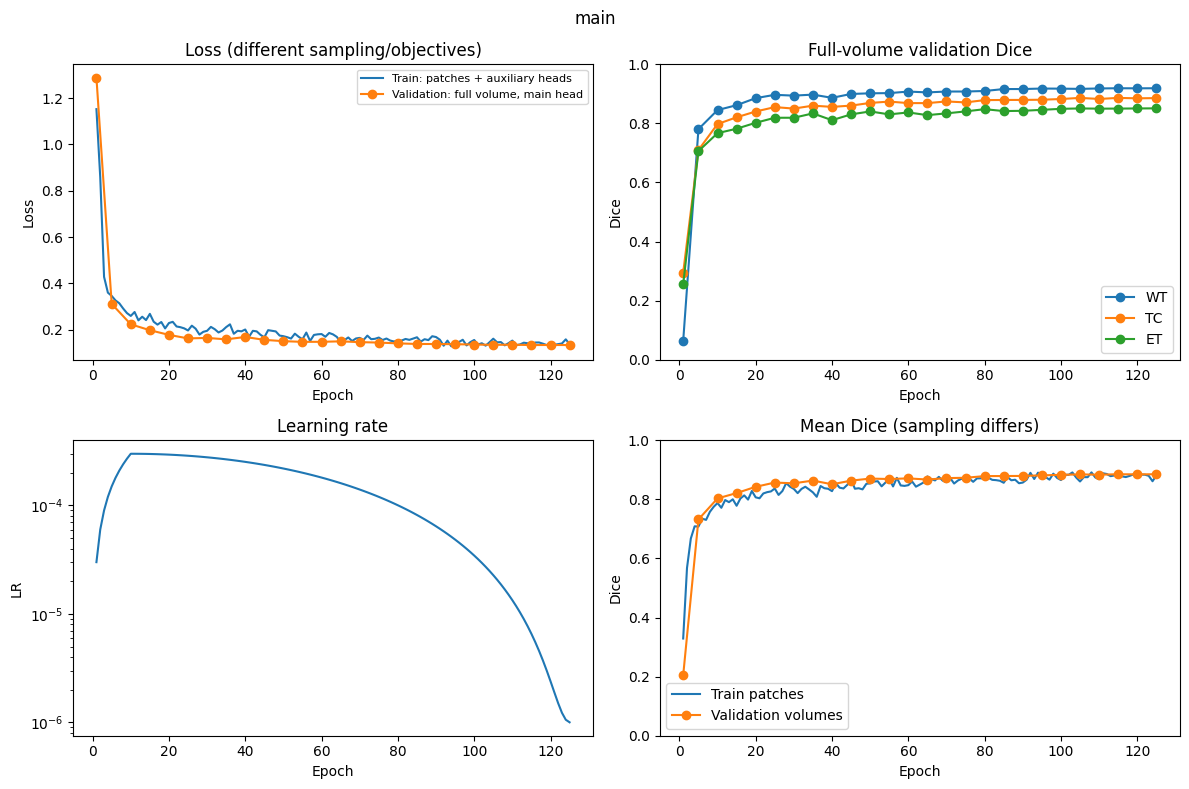

In [14]:
SEED_RUNS = [("main", "main", cfg.seed)] + (
    [(f"main_s{s}", "main", s) for s in cfg.extra_seeds] if cfg.run_seed_repeats else []
)
ABLATION_RUNS = [(f"abl_{v}", v, cfg.seed) for v in cfg.ablations] if cfg.run_ablations else []
PLANNED_RUNS = SEED_RUNS + ABLATION_RUNS
RUN_INFO = {name: dict(variant=variant, seed=seed) for name, variant, seed in PLANNED_RUNS}


def run_complete(name, epochs=None):
    epochs = epochs or cfg.epochs
    progress = run_progress(OUT / name)
    return (OUT / name / "best.pt").exists() and progress >= epochs


def ensure_trained(name, variant="main", seed=None, epochs=None, teacher=None):
    epochs = epochs or cfg.epochs
    if run_complete(name, epochs):
        print(f"{name}: complete, not retrained")
        return True
    last = OUT / name / "last.pt"
    train_experiment(
        name, variant, teacher, epochs, resume=str(last) if last.exists() else "", seed=seed
    )
    return run_complete(name, epochs)


if cfg.run_training:
    for name, variant, seed in PLANNED_RUNS:
        if cfg.only_runs and name not in cfg.only_runs:
            continue
        if name == "main" and cfg.resume_path:
            train_experiment("main", resume=cfg.resume_path)
            if not run_complete("main"):
                break
        elif not ensure_trained(name, variant, seed):
            print(f"Stopping the queue at {name}; later runs start in the next session.")
            break
    if cfg.run_baseline and run_complete("main"):
        ensure_trained("baseline", "baseline")
    if cfg.run_student and run_complete("main"):
        teacher, _ = load_best("main")
        ensure_trained("student", epochs=cfg.student_epochs, teacher=teacher)
        del teacher
else:
    print("Training disabled. Evaluating whichever planned runs are already complete.")

experiment_names = [name for name, _, _ in PLANNED_RUNS if run_complete(name)]
experiment_names += ["baseline"] if cfg.run_baseline and run_complete("baseline") else []
experiment_names += (
    ["student"] if cfg.run_student and run_complete("student", cfg.student_epochs) else []
)
pending = [name for name, _, _ in PLANNED_RUNS if name not in experiment_names]
print("Complete runs:", experiment_names)
print("Still to train:", pending or "none")


def plot_history(name):
    h = pd.read_csv(OUT / name / "history.csv")
    v = h.dropna(subset=["val_mean_dice"])
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes[0, 0].plot(h.epoch, h.train_loss, label="Train: patches + auxiliary heads")
    axes[0, 0].plot(v.epoch, v.val_loss, "o-", label="Validation: full volume, main head")
    axes[0, 0].set(title="Loss (different sampling/objectives)", xlabel="Epoch", ylabel="Loss")
    axes[0, 0].legend(fontsize=8)
    for r in REGIONS:
        axes[0, 1].plot(v.epoch, v[f"val_dice_{r}"], "o-", label=r)
    axes[0, 1].set(title="Full-volume validation Dice", xlabel="Epoch", ylabel="Dice", ylim=(0, 1))
    axes[0, 1].legend()
    axes[1, 0].plot(h.epoch, h.lr)
    axes[1, 0].set(title="Learning rate", xlabel="Epoch", ylabel="LR", yscale="log")
    axes[1, 1].plot(h.epoch, h.train_patch_dice, label="Train patches")
    axes[1, 1].plot(v.epoch, v.val_mean_dice, "o-", label="Validation volumes")
    axes[1, 1].set(title="Mean Dice (sampling differs)", xlabel="Epoch", ylabel="Dice", ylim=(0, 1))
    axes[1, 1].legend()
    fig.suptitle(name + (" — SMOKE ONLY" if cfg.smoke_test else ""))
    fig.tight_layout()
    fig.savefig(OUT / name / "learning_curves.png", dpi=180)
    plt.show()


for name in experiment_names:
    plot_history(name)

In [15]:
EXPORT_DIR = OUT / "exported_models"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

for name in experiment_names:
    best_path = OUT / name / "best.pt"
    if not best_path.is_file():
        print(f"Skipping {name}: no trained checkpoint at {best_path}")
        continue

    trained_model, best_ckpt = load_best(name)
    export_path = EXPORT_DIR / f"{name}_model.pth"
    torch.save(
        {
            "state_dict": {k: v.detach().cpu() for k, v in trained_model.state_dict().items()},
            "base": best_ckpt["base"],
            "variant": best_ckpt["variant"],
            "epoch": best_ckpt["epoch"],
            "val_score": best_ckpt["val_score"],
        },
        export_path,
    )
    print(f"Saved {name} → {export_path} (validation Dice: {best_ckpt['val_score']:.4f})")
    del trained_model

Saved main → /kaggle/working/moreg/full/exported_models/main_model.pth (validation Dice: 0.8852)


In [16]:
MODEL_NAME = "main"
MODEL_FILE = EXPORT_DIR / f"{MODEL_NAME}_model.pth"
if not MODEL_FILE.is_file():
    raise FileNotFoundError(f"Export not found: {MODEL_FILE}. Run the saving cell first.")

saved = torch.load(MODEL_FILE, map_location="cpu", weights_only=True)
loaded_model = MoReGSeg(saved["base"], saved["variant"]).to(DEVICE)
loaded_model.load_state_dict(saved["state_dict"], strict=True)
loaded_model.eval()
print(f"Loaded {MODEL_NAME} model from {MODEL_FILE}")
print(f"Selected epoch: {saved['epoch']} | validation Dice: {saved['val_score']:.4f}")

Loaded main model from /kaggle/working/moreg/full/exported_models/main_model.pth
Selected epoch: 125 | validation Dice: 0.8852


In [17]:
def bootstrap_mean(values, seed=None):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return np.nan, np.nan
    rng = np.random.default_rng(cfg.seed if seed is None else seed)
    means = [
        rng.choice(values, len(values), replace=True).mean() for _ in range(cfg.bootstrap_samples)
    ]
    return tuple(np.percentile(means, [2.5, 97.5]))


def summarize(df):
    metrics = [
        "dice",
        "iou",
        "precision",
        "recall",
        "specificity",
        "voxel_accuracy",
        "hd95_mm",
        "surface_dice",
    ]
    rows = []
    for r, group in df.groupby("region", sort=False):
        for metric in metrics:
            values = group[metric].to_numpy(dtype=float)
            finite = values[np.isfinite(values)]
            low, high = bootstrap_mean(finite)
            rows.append(
                dict(
                    region=r,
                    metric=metric,
                    mean=float(finite.mean()) if len(finite) else np.nan,
                    median=float(np.median(finite)) if len(finite) else np.nan,
                    std=float(finite.std(ddof=1)) if len(finite) > 1 else np.nan,
                    ci95_low=low,
                    ci95_high=high,
                    n_patients=len(values),
                    n_finite=len(finite),
                    n_nan=int(np.isnan(values).sum()),
                    n_infinite=int(np.isinf(values).sum()),
                    population="finite cases only" if np.isinf(values).any() else "defined cases",
                )
            )
        present = group.loc[group.gt_present, "dice"].to_numpy()
        low, high = bootstrap_mean(present)
        rows.append(
            dict(
                region=r,
                metric="dice_GT_present",
                mean=np.mean(present) if len(present) else np.nan,
                ci95_low=low,
                ci95_high=high,
                n_patients=len(group),
                n_finite=len(present),
                n_nan=0,
                n_infinite=0,
                population="GT-present cases only",
            )
        )
    return pd.DataFrame(rows)


def patient_macro(df):
    return df.pivot(index="case_id", columns="region", values="dice")[list(REGIONS)].mean(axis=1)


def apply_et_rule(df, et_min_voxels):
    out = df.copy()
    hit = (out.region == "ET") & (out.pred_voxels > 0) & (out.pred_voxels < et_min_voxels)
    out["et_rule_removed"] = hit
    if not hit.any():
        return out
    rows = out.loc[hit]
    gt = rows.gt_voxels.astype(int)
    has_gt = gt > 0
    tn = (rows.tn + rows.fp).astype(int)
    out.loc[hit, "tn"] = tn
    out.loc[hit, "tp"] = 0
    out.loc[hit, "fp"] = 0
    out.loc[hit, "fn"] = gt
    out.loc[hit, "pred_voxels"] = 0
    out.loc[hit, "pred_ml"] = 0.0
    out.loc[hit, "empty_false_positive"] = False
    out.loc[hit, "dice"] = np.where(has_gt, 0.0, 1.0)
    out.loc[hit, "iou"] = np.where(has_gt, 0.0, 1.0)
    out.loc[hit, "precision"] = np.nan
    out.loc[hit, "recall"] = np.where(has_gt, 0.0, np.nan)
    out.loc[hit, "specificity"] = np.where(tn > 0, 1.0, np.nan)
    out.loc[hit, "voxel_accuracy"] = tn / (tn + gt)
    if "hd95_mm" in out:
        out.loc[hit, "hd95_mm"] = np.where(has_gt, np.inf, 0.0)
        out.loc[hit, "surface_dice"] = np.where(has_gt, 0.0, 1.0)
    return out


def tune_et_threshold(val_df, grid=None):
    grid = sorted(cfg.et_volume_grid if grid is None else grid)
    rows = []
    for t in grid:
        et = apply_et_rule(val_df, t)
        et = et[et.region == "ET"]
        rows.append(
            dict(
                et_min_voxels=t,
                val_et_dice=float(et.dice.mean()),
                val_macro_dice=float(patient_macro(apply_et_rule(val_df, t)).mean()),
                et_absent_patients=int((~et.gt_present).sum()),
                et_absent_false_positives=int(et.empty_false_positive.sum()),
                et_present_removed=int((et.et_rule_removed & et.gt_present).sum()),
            )
        )
    table = pd.DataFrame(rows)
    best = table.val_et_dice.max()
    chosen = int(
        table.loc[np.isclose(table.val_et_dice, best, rtol=0, atol=1e-12)].et_min_voxels.min()
    )
    return chosen, table


def paired_bootstrap(a, b, seed=None):
    a, b = a.align(b, join="inner")
    d = (b - a).to_numpy(dtype=float)
    low, high = bootstrap_mean(d, seed)
    return float(d.mean()), low, high, len(d)

In [18]:
def plot_test(df, summary, examples, folder):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, metric, title in zip(
        axes[0],
        ["dice", "iou", "hd95_mm"],
        ["Dice by patient", "IoU by patient", "HD95 (finite cases only)"],
    ):
        arrays = [
            df.loc[df.region == r, metric].replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
            for r in REGIONS
        ]
        ax.boxplot([a if len(a) else [np.nan] for a in arrays], tick_labels=REGIONS, showmeans=True)
        ax.set(title=title, ylabel="mm" if metric == "hd95_mm" else metric)
        if metric != "hd95_mm":
            ax.set_ylim(0, 1.03)
        else:
            ax.text(
                0.02,
                0.96,
                f"Infinite failures: {int(np.isinf(df[metric]).sum())}",
                transform=ax.transAxes,
                va="top",
            )
    for r in REGIONS:
        d = df[df.region == r]
        axes[1, 0].scatter(d.gt_ml, d.dice, s=15, alpha=0.6, label=r)
    axes[1, 0].set(
        xlabel="GT tumor volume (mL)",
        ylabel="Dice",
        title="Small-tumor performance",
        xscale="symlog",
        ylim=(0, 1.03),
    )
    axes[1, 0].legend()
    sm = summary[summary.metric == "dice"].set_index("region").loc[list(REGIONS)]
    lo = np.maximum(0, sm["mean"] - sm.ci95_low)
    hi = np.maximum(0, sm.ci95_high - sm["mean"])
    axes[1, 1].bar(
        REGIONS,
        sm["mean"],
        yerr=np.stack([lo, hi]),
        capsize=5,
        color=["#5470c6", "#58a687", "#cc785c"],
    )
    axes[1, 1].set(title="Patient bootstrap 95% CI", ylabel="Mean Dice", ylim=(0, 1.05))
    latency = df.drop_duplicates("case_id").inference_seconds
    axes[1, 2].hist(latency, bins=min(15, len(latency)))
    axes[1, 2].set(
        title="Inference incl. tiling/CPU merge/TTA", xlabel="Seconds per case", ylabel="Patients"
    )
    fig.tight_layout()
    fig.savefig(folder / "test_dashboard.png", dpi=180)
    plt.show()
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for ax, r in zip(axes, REGIONS):
        d = df[df.region == r]
        cm = np.array([[d.tn.sum(), d.fp.sum()], [d.fn.sum(), d.tp.sum()]], dtype=float)
        normalized = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(normalized, vmin=0, vmax=1, cmap="Blues")
        for i, j in itertools.product(range(2), repeat=2):
            ax.text(
                j,
                i,
                f"{cm[i,j]:,.0f}\n({normalized[i,j]:.3f})",
                ha="center",
                va="center",
                color="white" if normalized[i, j] > 0.6 else "black",
                fontsize=8,
            )
        ax.set(
            xticks=[0, 1],
            yticks=[0, 1],
            xticklabels=["Absent", "Present"],
            yticklabels=["Absent", "Present"],
            xlabel="Predicted",
            ylabel="Ground truth",
            title=r,
        )
    fig.suptitle("Voxel confusion matrices: rows normalized; counts pooled across patients")
    fig.tight_layout()
    fig.savefig(folder / "confusion_matrices.png", dpi=180)
    plt.show()

    cmap = ListedColormap(["black", "#4bb3fd", "#f2c14e", "#ef476f"])
    for cid, flair, gt, pred in examples:
        z = int(np.argmax((gt > 0).sum((0, 1))))

        def remap(a):
            return np.select([a == 1, a == 2, a == 4], [1, 2, 3], 0)

        error = np.zeros_like(gt)
        error[(gt == 0) & (pred > 0)] = 1
        error[(gt > 0) & (pred == 0)] = 2
        error[(gt > 0) & (pred > 0) & (gt != pred)] = 3
        fig, axes = plt.subplots(1, 4, figsize=(14, 4))
        for ax in axes:
            ax.imshow(flair[:, :, z].T, cmap="gray", origin="lower")
            ax.axis("off")
        axes[1].imshow(
            np.ma.masked_equal(remap(gt[:, :, z].T), 0),
            cmap=cmap,
            vmin=0,
            vmax=3,
            alpha=0.7,
            origin="lower",
        )
        axes[2].imshow(
            np.ma.masked_equal(remap(pred[:, :, z].T), 0),
            cmap=cmap,
            vmin=0,
            vmax=3,
            alpha=0.7,
            origin="lower",
        )
        axes[3].imshow(
            np.ma.masked_equal(error[:, :, z].T, 0),
            cmap=ListedColormap(["black", "red", "cyan", "yellow"]),
            vmin=0,
            vmax=3,
            alpha=0.8,
            origin="lower",
        )
        for ax, title in zip(
            axes,
            [
                "FLAIR",
                "GT: blue=NCR, gold=ED, pink=ET",
                "Prediction",
                "Errors: red=FP, cyan=FN, yellow=subtype",
            ],
        ):
            ax.set_title(title, fontsize=9)
        fig.suptitle(f"{cid} | axial z={z} (largest GT tumor slice)")
        fig.tight_layout()
        fig.savefig(folder / f"{cid}_overlay.png", dpi=180)
        plt.show()

main: ET volume threshold chosen on validation = 750 voxels


,et_min_voxels,val_et_dice,val_macro_dice,et_absent_patients,et_absent_false_positives,et_present_removed
0,0,0.851000,0.885243,5,2,0
1,25,0.851000,0.885243,5,2,0
2,50,0.851000,0.885243,5,2,0
3,100,0.849698,0.884809,5,2,1
4,150,0.849698,0.884809,5,2,1
5,200,0.849698,0.884809,5,2,1
6,300,0.849698,0.884809,5,2,1
7,400,0.849698,0.884809,5,2,1
8,500,0.855017,0.886582,5,1,1
9,750,0.856165,0.886964,5,0,2


Full-volume evaluation:   0%|          | 0/188 [00:00<?, ?it/s]

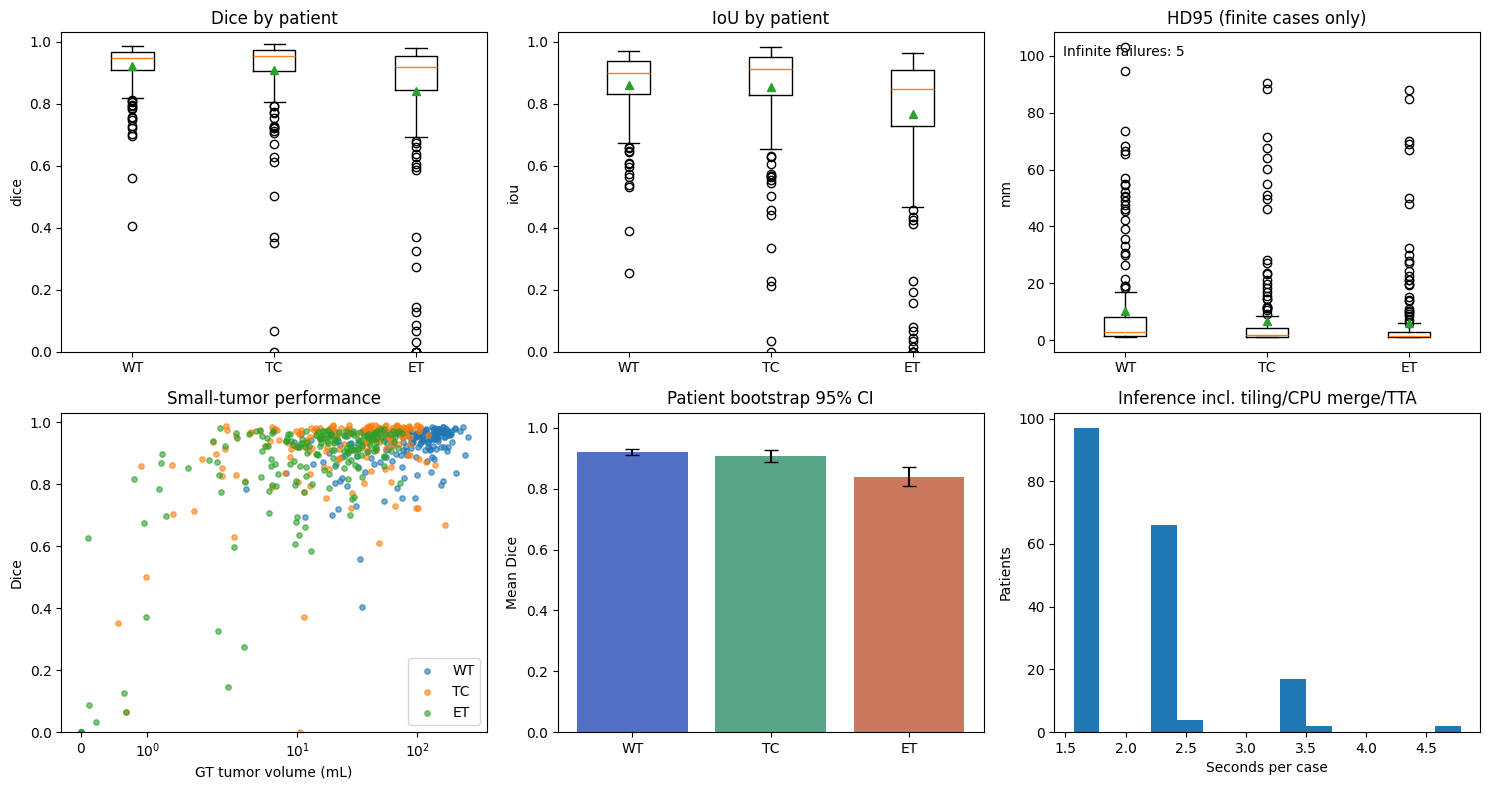

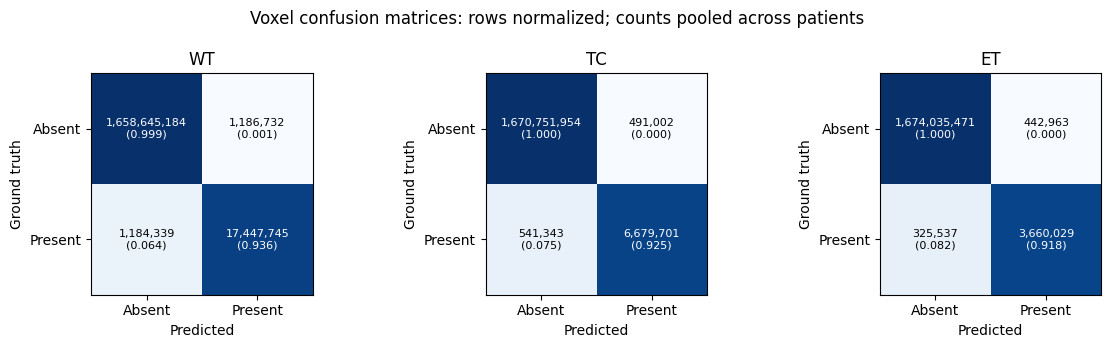

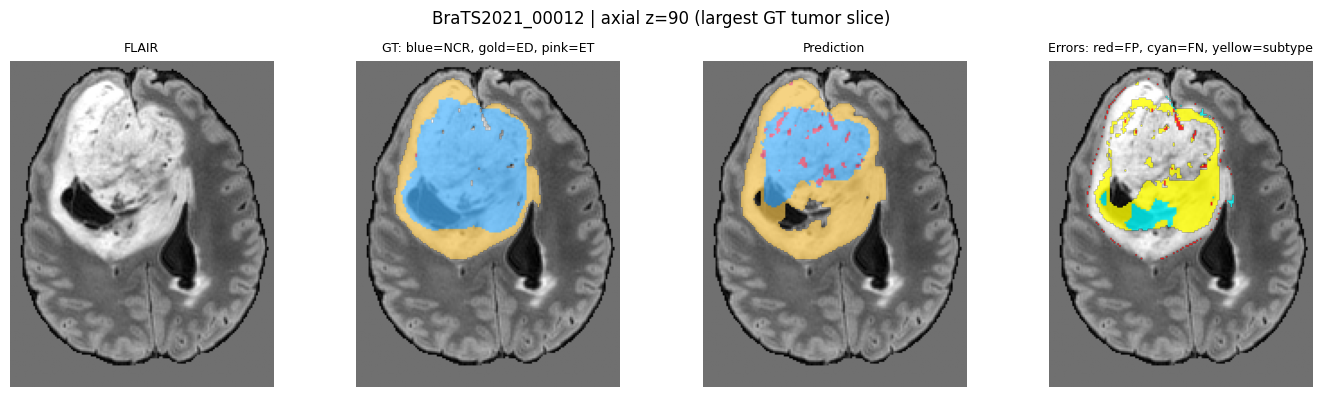

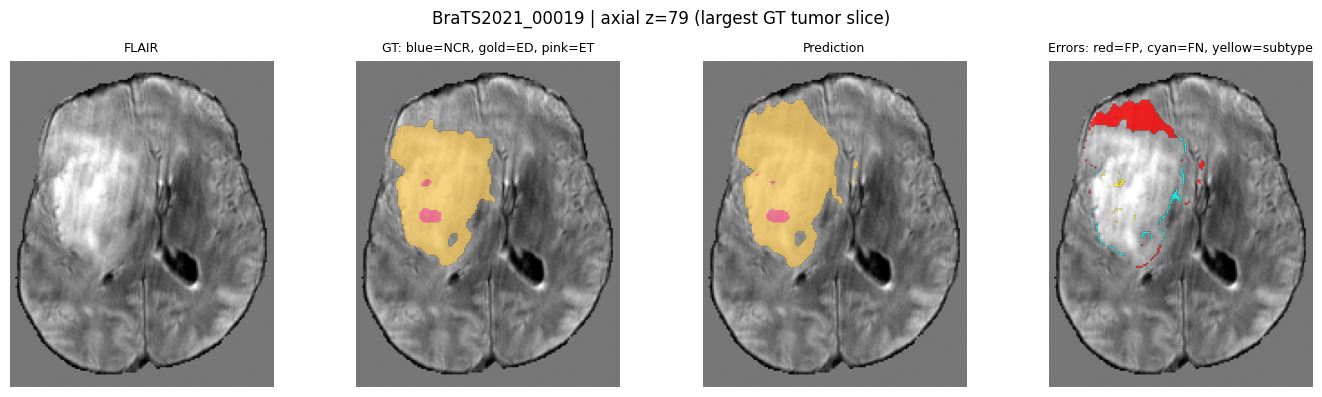

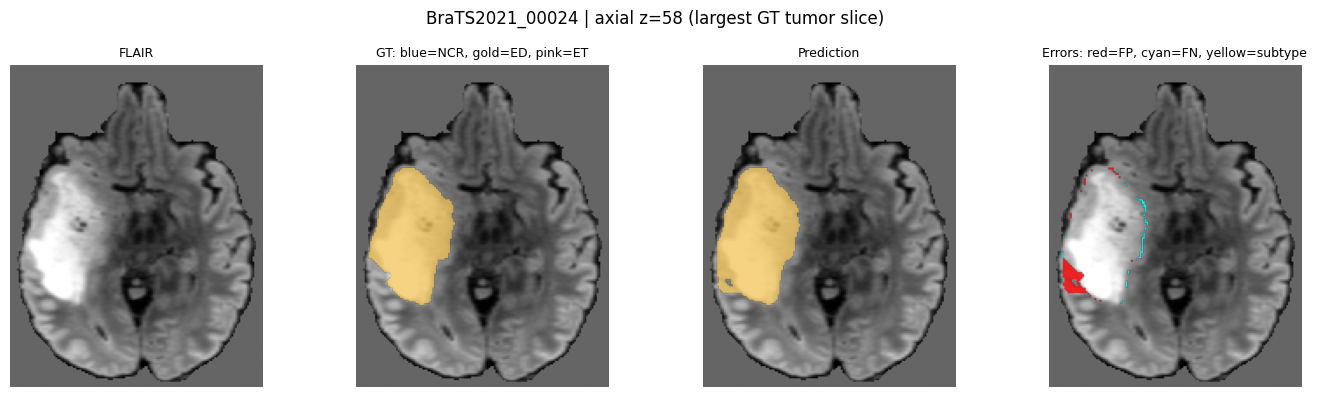

main


,pipeline,et_min_voxels,mean_patient_macro_dice,ci95_low,ci95_high,et_absent_false_positives,hd95_infinite_failures
0,raw,0,0.889983,0.872298,0.906036,5,5
1,et_volume_rule,750,0.891644,0.874849,0.907230,3,6


In [19]:
def overview_row(df, ck, et_min_voxels, pipeline):
    macro = patient_macro(df)
    low, high = bootstrap_mean(macro)
    et = df[df.region == "ET"]
    return dict(
        pipeline=pipeline,
        et_min_voxels=et_min_voxels,
        mean_patient_macro_dice=float(macro.mean()),
        ci95_low=low,
        ci95_high=high,
        n_test_patients=len(macro),
        selected_epoch=ck["epoch"],
        validation_dice_at_selection=ck["val_score"],
        threshold=cfg.threshold,
        tta=cfg.tta,
        surface_tolerance_mm=cfg.surface_tolerance_mm,
        smoke_only=cfg.smoke_test,
        hd95_infinite_failures=int(np.isinf(df.hd95_mm).sum()),
        et_absent_patients=int((~et.gt_present).sum()),
        et_absent_false_positives=int(et.empty_false_positive.sum()),
        inference_seconds_median=float(df.drop_duplicates("case_id").inference_seconds.median()),
    )


def cached_test_metrics(folder, ck):
    metrics_path, overview_path = folder / "patient_metrics.csv", folder / "overview.csv"
    if not (metrics_path.exists() and overview_path.exists()):
        return None
    ov = pd.read_csv(overview_path).iloc[0]
    same = (
        int(ov.selected_epoch) == int(ck["epoch"])
        and bool(ov.smoke_only) == cfg.smoke_test
        and float(ov.threshold) == cfg.threshold
        and bool(ov.tta) == cfg.tta
    )
    return pd.read_csv(metrics_path, dtype={"case_id": str}) if same else None


RESULTS = {}
for name in experiment_names:
    model, checkpoint = load_best(name)
    run_dir = OUT / name
    folder = run_dir / "test"
    folder.mkdir(parents=True, exist_ok=True)

    et_min_voxels = 0
    if cfg.et_postprocess:
        val_path = run_dir / "best_validation_patients.csv"
        if val_path.exists():
            val_df = pd.read_csv(val_path, dtype={"case_id": str})
        else:
            val_df, _, _ = evaluate(model, files["val"], surfaces=False)
            val_df.to_csv(val_path, index=False)
        et_min_voxels, tuning = tune_et_threshold(val_df)
        tuning.to_csv(run_dir / "et_rule_validation_tuning.csv", index=False)
        print(f"{name}: ET volume threshold chosen on validation = {et_min_voxels} voxels")
        display(tuning)

    metrics = cached_test_metrics(folder, checkpoint)
    examples = []
    if metrics is None:
        metrics, _, examples = evaluate(
            model,
            files["test"],
            surfaces=True,
            out_dir=folder,
            save_examples=cfg.save_nifti_count if name == "main" else 0,
            et_min_voxels=et_min_voxels,
        )
        metrics.to_csv(folder / "patient_metrics.csv", index=False)
        summary = summarize(metrics)
        summary.to_csv(folder / "metric_summary.csv", index=False)
        atomic_csv(
            pd.DataFrame([overview_row(metrics, checkpoint, 0, "raw")]), folder / "overview.csv"
        )
        if name == "main":
            plot_test(metrics, summary, examples, folder)
    else:
        print(f"{name}: reusing saved raw test metrics for epoch {checkpoint['epoch']}")

    post = apply_et_rule(metrics, et_min_voxels)
    post.to_csv(folder / "postproc_patient_metrics.csv", index=False)
    summarize(post).to_csv(folder / "postproc_metric_summary.csv", index=False)
    both = pd.DataFrame(
        [
            overview_row(metrics, checkpoint, 0, "raw"),
            overview_row(post, checkpoint, et_min_voxels, "et_volume_rule"),
        ]
    )
    atomic_csv(both, folder / "overview_raw_vs_postproc.csv")
    empty_report = pd.concat(
        {
            p: d.groupby("region").agg(
                gt_absent=("gt_present", lambda a: int((~a).sum())),
                empty_false_positives=("empty_false_positive", "sum"),
            )
            for p, d in (("raw", metrics), ("et_volume_rule", post))
        }
    )
    empty_report.to_csv(folder / "empty_region_report.csv")
    print(name)
    display(
        both[
            [
                "pipeline",
                "et_min_voxels",
                "mean_patient_macro_dice",
                "ci95_low",
                "ci95_high",
                "et_absent_false_positives",
                "hd95_infinite_failures",
            ]
        ]
    )

    RESULTS[name] = dict(
        raw=metrics,
        post=post,
        et_min_voxels=et_min_voxels,
        epoch=int(checkpoint["epoch"]),
        val_score=float(checkpoint["val_score"]),
        seed=int(checkpoint["seed"]),
        variant=checkpoint["variant"],
        params=sum(p.numel() for p in model.parameters()),
    )
    test_results = {k: v["raw"] for k, v in RESULTS.items()}
    del model, examples
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

In [20]:
ABLATION_LABELS = {
    "no_gate": ("NoGate", "w/o skip gates"),
    "no_context": ("NoContext", "w/o dilated context"),
    "uniform_fusion": ("UniformFusion", "uniform fusion weights"),
}
PENDING = r"\Pending"


def pct(x):
    return f"{100 * x:.2f}"


def signed(x):
    return ("$-$" if x < 0 else "+") + f"{abs(x):.2f}"


def ci_text(low, high):
    return f"{signed(low)} to {signed(high)}"


def word_list(items):
    items = [str(i) for i in items]
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + ", and " + items[-1]


def region_dice(df, region):
    return float(df.loc[df.region == region, "dice"].mean())


def run_row(name):
    r = RESULTS[name]
    raw, post = r["raw"], r["post"]
    et_raw, et_post = raw[raw.region == "ET"], post[post.region == "ET"]
    return dict(
        name=name,
        seed=r["seed"],
        variant=r["variant"],
        epoch=r["epoch"],
        val_dice=r["val_score"],
        params=r["params"],
        T=r["et_min_voxels"],
        WT=region_dice(raw, "WT"),
        TC=region_dice(raw, "TC"),
        ET=region_dice(raw, "ET"),
        macro=float(patient_macro(raw).mean()),
        ET_post=region_dice(post, "ET"),
        macro_post=float(patient_macro(post).mean()),
        et_absent=int((~et_raw.gt_present).sum()),
        et_fp=int(et_raw.empty_false_positive.sum()),
        et_fp_post=int(et_post.empty_false_positive.sum()),
    )


def build_paper_macros(results):
    m = {}
    seed_names = [n for n, v, s in SEED_RUNS if n in results]
    seeds = [s for _, _, s in SEED_RUNS]
    m["SeedList"] = word_list(seeds)
    m["NSeedsPlanned"] = str(len(seeds))
    rows = pd.DataFrame([run_row(n) for n in seed_names])

    keys = [
        "SeedMacroRaw",
        "SeedWTRaw",
        "SeedTCRaw",
        "SeedETRaw",
        "SeedMacroPost",
        "SeedETPost",
        "SeedMacroSD",
        "SeedMacroRange",
        "SeedETFPRange",
        "SeedETFPPostRange",
        "SeedThresholds",
        "NSeeds",
        "SeedDiffSpread",
    ]
    m.update({k: PENDING for k in keys})
    seed_sd = None
    table = []
    for _, r in rows.iterrows():
        table.append(
            f"{r.seed} & {pct(r.WT)} & {pct(r.TC)} & {pct(r.ET)} & {pct(r.macro)} & "
            f"{r.et_fp}/{r.et_absent} & {r['T']} & {pct(r.macro_post)}"
        )
    for n, _, s in SEED_RUNS:
        if n not in results:
            table.append(f"{s} & \\multicolumn{{7}}{{c|}}{{{PENDING}}}")
    if len(rows) >= 2:

        def pm(col):
            return f"{pct(rows[col].mean())} $\\pm$ {pct(rows[col].std(ddof=1))}"

        seed_sd = float(rows.macro.std(ddof=1))
        m.update(
            SeedMacroRaw=pm("macro"),
            SeedWTRaw=pm("WT"),
            SeedTCRaw=pm("TC"),
            SeedETRaw=pm("ET"),
            SeedMacroPost=pm("macro_post"),
            SeedETPost=pm("ET_post"),
            SeedMacroSD=pct(seed_sd),
            SeedDiffSpread=pct(math.sqrt(2) * seed_sd),
            SeedMacroRange=f"{pct(rows.macro.min())}--{pct(rows.macro.max())}",
            SeedETFPRange=(
                f"{rows.et_fp.min()}--{rows.et_fp.max()}"
                if rows.et_fp.min() != rows.et_fp.max()
                else str(rows.et_fp.min())
            ),
            SeedETFPPostRange=(
                f"{rows.et_fp_post.min()}--{rows.et_fp_post.max()}"
                if rows.et_fp_post.min() != rows.et_fp_post.max()
                else str(rows.et_fp_post.min())
            ),
            SeedThresholds=word_list(rows["T"].tolist()),
            NSeeds=str(len(rows)),
        )
        for label, fn in (("Mean", "mean"), ("SD", "std")):
            vals = [
                pct(getattr(rows[c], fn)(**({"ddof": 1} if fn == "std" else {})))
                for c in ("WT", "TC", "ET", "macro")
            ]
            post_val = pct(getattr(rows.macro_post, fn)(**({"ddof": 1} if fn == "std" else {})))
            table.append(f"{label} & " + " & ".join(vals) + f" & -- & -- & {post_val}")
    m["SeedTableRows"] = " \\\\\\hline\n".join(table) + " \\\\\\hline"

    et_keys = [
        "ETThreshold",
        "ETAbsentN",
        "ETValAbsentN",
        "ETFPRaw",
        "ETFPPost",
        "ETRemovedPresent",
        "MacroPost",
        "MacroPostCI",
        "ETDicePost",
        "ETDicePostCI",
        "ETPresentDicePost",
        "ETInfRaw",
        "ETInfPost",
    ]
    m.update({k: PENDING for k in et_keys})
    m["ETTableRows"] = f"\\multicolumn{{3}}{{|c|}}{{{PENDING}}} \\\\\\hline"
    if "main" in results:
        r = results["main"]
        raw, post, T = r["raw"], r["post"], r["et_min_voxels"]
        tuning = pd.read_csv(OUT / "main" / "et_rule_validation_tuning.csv")

        def stats(df):
            et = df[df.region == "ET"]
            macro = patient_macro(df)
            present = et.loc[et.gt_present, "dice"]
            return dict(
                macro=macro.mean(),
                macro_ci=bootstrap_mean(macro),
                et=et.dice.mean(),
                et_ci=bootstrap_mean(et.dice),
                et_present=present.mean(),
                fp=int(et.empty_false_positive.sum()),
                absent=int((~et.gt_present).sum()),
                inf=int(np.isinf(et.hd95_mm).sum()),
                removed=int((et.get("et_rule_removed", False) & et.gt_present).sum()),
            )

        a, b = stats(raw), stats(post)
        m.update(
            ETThreshold=str(T),
            ETAbsentN=str(a["absent"]),
            ETValAbsentN=str(int(tuning.et_absent_patients.iloc[0])),
            ETFPRaw=str(a["fp"]),
            ETFPPost=str(b["fp"]),
            ETRemovedPresent=str(b["removed"]),
            MacroPost=pct(b["macro"]),
            MacroPostCI=f"{pct(b['macro_ci'][0])}--{pct(b['macro_ci'][1])}",
            ETDicePost=pct(b["et"]),
            ETDicePostCI=f"{pct(b['et_ci'][0])}--{pct(b['et_ci'][1])}",
            ETPresentDicePost=pct(b["et_present"]),
            ETInfRaw=str(a["inf"]),
            ETInfPost=str(b["inf"]),
        )

        def ci(s, key):
            return f"{pct(s[key])} [{pct(s[key + '_ci'][0])}, {pct(s[key + '_ci'][1])}]"

        m["ETTableRows"] = (
            " \\\\\\hline\n".join(
                [
                    f"Patient-macro Dice [95\\% CI] & {ci(a, 'macro')} & {ci(b, 'macro')}",
                    f"ET Dice, all patients [95\\% CI] & {ci(a, 'et')} & {ci(b, 'et')}",
                    f"ET Dice, ET-present patients & {pct(a['et_present'])} & {pct(b['et_present'])}",
                    f"ET false positives (ET-absent) & {a['fp']} of {a['absent']} & "
                    f"{b['fp']} of {b['absent']}",
                    f"ET-present patients emptied & 0 & {b['removed']}",
                    f"Infinite ET HD95 & {a['inf']} & {b['inf']}",
                ]
            )
            + " \\\\\\hline"
        )

    m["AblMainParams"] = f"{results['main']['params'] / 1e6:.2f}" if "main" in results else PENDING
    abl_table = []
    if "main" in results:
        mr = run_row("main")
        abl_table.append(
            f"MoReG (full) & {mr['params'] / 1e6:.2f} & {pct(mr['macro'])} & {pct(mr['ET'])} "
            f"& -- & --"
        )
    for v in cfg.ablations:
        key, label = ABLATION_LABELS[v]
        name = f"abl_{v}"
        for k in ("Params", "Macro", "ET", "Delta", "CI", "ETDelta", "Verdict"):
            m[f"Abl{key}{k}"] = PENDING
        if name not in results or "main" not in results:
            abl_table.append(f"{label} & \\multicolumn{{5}}{{c|}}{{{PENDING}}}")
            continue
        r = run_row(name)
        main_raw, abl_raw = results["main"]["raw"], results[name]["raw"]
        d, lo, hi, _ = paired_bootstrap(patient_macro(main_raw), patient_macro(abl_raw))
        et_main = main_raw[main_raw.region == "ET"].set_index("case_id").dice
        et_abl = abl_raw[abl_raw.region == "ET"].set_index("case_id").dice
        de, _, _, _ = paired_bootstrap(et_main, et_abl)
        excludes_zero = lo > 0 or hi < 0
        if seed_sd is None:
            verdict = (
                "not yet comparable with the seed spread (fewer than two seeds), and its "
                "paired interval " + ("excludes" if excludes_zero else "includes") + " zero"
            )
        else:
            beyond = abs(d) > math.sqrt(2) * seed_sd
            verdict = (
                ("larger than" if beyond else "within")
                + " the expected seed spread, and its paired interval "
                + ("excludes" if excludes_zero else "includes")
                + " zero"
            )
        m.update(
            {
                f"Abl{key}Params": f"{r['params'] / 1e6:.2f}",
                f"Abl{key}Macro": pct(r["macro"]),
                f"Abl{key}ET": pct(r["ET"]),
                f"Abl{key}Delta": signed(100 * d),
                f"Abl{key}CI": ci_text(100 * lo, 100 * hi),
                f"Abl{key}ETDelta": signed(100 * de),
                f"Abl{key}Verdict": verdict,
            }
        )
        abl_table.append(
            f"{label} & {r['params'] / 1e6:.2f} & {pct(r['macro'])} & {pct(r['ET'])} & "
            f"{signed(100 * d)} [{signed(100 * lo)}, {signed(100 * hi)}] & {signed(100 * de)}"
        )
    m["AblTableRows"] = " \\\\\\hline\n".join(abl_table) + " \\\\\\hline"
    return m


def write_paper_macros(macros, path):
    lines = [
        "% Generated by the MoReG notebook. Do not edit by hand; rerun the notebook instead.",
        "\\providecommand{\\Pending}{\\textbf{[pending]}}",
    ]
    lines += [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in macros.items()]
    Path(path).write_text("\n".join(lines) + "\n")


paper_macros = build_paper_macros(RESULTS)
write_paper_macros(paper_macros, OUT / "paper_results.tex")
pd.DataFrame([run_row(n) for n in RESULTS]).to_csv(OUT / "all_runs_summary.csv", index=False)
display(pd.DataFrame([run_row(n) for n in RESULTS]))
print(
    "Wrote",
    OUT / "paper_results.tex",
    "| pending macros:",
    sum(v == PENDING for v in paper_macros.values()),
)

,name,seed,variant,epoch,val_dice,params,T,WT,TC,ET,macro,ET_post,macro_post,et_absent,et_fp,et_fp_post
0,main,42,main,125,0.885243,4656916,750,0.92105,0.908838,0.840061,0.889983,0.845045,0.891644,5,5,3


Wrote /kaggle/working/moreg/full/paper_results.tex | pending macros: 34
